In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile

zip_path = '/content/drive/MyDrive/Colab Notebooks/severstal-steel-defect-detection.zip'  # change if needed
extract_dir = '/content/steel_data'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)

print("✅ Extraction completed successfully!")


✅ Extraction completed successfully!


In [ ]:
import os

train_dir = "/content/drive/MyDrive/Feedstock_ViT_Project/steel_data/train_images"
test_dir = "/content/drive/MyDrive/Feedstock_ViT_Project/steel_data/test_images"

print("Train Images:", len(os.listdir(train_dir)))
print("Test Images:", len(os.listdir(test_dir)))


Train Images: 12568
Test Images: 5506


In [ ]:
import pandas as pd

train_csv = pd.read_csv("/content/drive/MyDrive/Feedstock_ViT_Project/steel_data/train.csv")
print(train_csv.head())


         ImageId  ClassId                                      EncodedPixels
0  0002cc93b.jpg        1  29102 12 29346 24 29602 24 29858 24 30114 24 3...
1  0007a71bf.jpg        3  18661 28 18863 82 19091 110 19347 110 19603 11...
2  000a4bcdd.jpg        1  37607 3 37858 8 38108 14 38359 20 38610 25 388...
3  000f6bf48.jpg        4  131973 1 132228 4 132483 6 132738 8 132993 11 ...
4  0014fce06.jpg        3  229501 11 229741 33 229981 55 230221 77 230468...


In [ ]:
# Simplify label mapping
train_csv['hasDefect'] = train_csv['EncodedPixels'].notnull().astype(int)

# Group by ImageId to mark if any class has a defect
image_labels = train_csv.groupby('ImageId')['hasDefect'].max().reset_index()

# Rename for consistency
image_labels.rename(columns={'ImageId': 'image'}, inplace=True)

print(image_labels.head())


           image  hasDefect
0  0002cc93b.jpg          1
1  0007a71bf.jpg          1
2  000a4bcdd.jpg          1
3  000f6bf48.jpg          1
4  0014fce06.jpg          1


In [ ]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(image_labels, test_size=0.2, stratify=image_labels['hasDefect'], random_state=42)
print("Train:", len(train_df), "Validation:", len(val_df))


Train: 5332 Validation: 1334


In [ ]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split

# --- Define paths ---
base_path = "/content/drive/MyDrive/Feedstock_ViT_Project/steel_data"
train_dir = os.path.join(base_path, "train_images")  # folder containing all training images (.jpg)
csv_path = os.path.join(base_path, "train.csv")

# --- Load and clean CSV ---
df = pd.read_csv(csv_path)
df["hasDefect"] = df["EncodedPixels"].notna().astype(int)
df = df.groupby("ImageId", as_index=False)["hasDefect"].max()
df.rename(columns={"ImageId": "image"}, inplace=True)

# --- Split data ---
train_df, val_df = train_test_split(df, test_size=0.2, stratify=df["hasDefect"], random_state=42)


In [ ]:
import tensorflow as tf
import cv2
import numpy as np

IMG_SIZE = 224

def preprocess_image(img_path, label):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0
    return img, label

def build_dataset(df):
    paths = [os.path.join(train_dir, fname) for fname in df['image']]
    labels = df['hasDefect'].values
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    dataset = dataset.map(preprocess_image).batch(16).prefetch(1)
    return dataset

train_ds = build_dataset(train_df)
val_ds = build_dataset(val_df)


In [ ]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from transformers import ViTImageProcessor, TFViTForImageClassification
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from PIL import Image


In [ ]:
data_dir = "/content/drive/MyDrive/Feedstock_ViT_Project/steel_data"  # change if different
csv_path = os.path.join(data_dir, "train.csv")  # Kaggle Severstal format


In [ ]:
df = pd.read_csv(csv_path)
df['hasDefect'] = df['EncodedPixels'].notnull().astype(int)

# Extract unique image IDs and labels
image_labels = df.groupby('ImageId')['hasDefect'].max().reset_index()

train_df, val_df = train_test_split(image_labels, test_size=0.2, stratify=image_labels['hasDefect'], random_state=42)


In [ ]:
IMG_SIZE = 224

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_gen = datagen.flow_from_dataframe(
    dataframe=train_df,
    directory=os.path.join(data_dir, "train_images"),
    x_col="ImageId",
    y_col="hasDefect",
    target_size=(IMG_SIZE, IMG_SIZE),
    class_mode="raw",
    batch_size=16,
    subset='training'
)

val_gen = datagen.flow_from_dataframe(
    dataframe=val_df,
    directory=os.path.join(data_dir, "train_images"),
    x_col="ImageId",
    y_col="hasDefect",
    target_size=(IMG_SIZE, IMG_SIZE),
    class_mode="raw",
    batch_size=16,
    subset='validation'
)


Found 4266 validated image filenames.
Found 266 validated image filenames.


In [ ]:
!pip install -q transformers torch torchvision pillow

from transformers import ViTModel, ViTImageProcessor
import torch
import tensorflow as tf
from tensorflow import keras
from keras import layers
import numpy as np

print("🔄 Loading PyTorch ViT (stable version)...")
vit_torch = ViTModel.from_pretrained("google/vit-base-patch16-224-in21k")
processor = ViTImageProcessor.from_pretrained("google/vit-base-patch16-224-in21k")

# --- PyTorch → TensorFlow wrapper ---
def vit_features_tf(image_batch):
    image_batch = image_batch.numpy()
    inputs = processor(images=image_batch, return_tensors="pt")
    with torch.no_grad():
        outputs = vit_torch(**inputs)
    return outputs.last_hidden_state[:, 0, :].cpu().numpy()

# --- Custom layer wrapper ---
class ViTLayer(tf.keras.layers.Layer):
    def call(self, inputs):
        x = tf.cast(inputs, tf.float32) / 255.0
        cls = tf.numpy_function(vit_features_tf, [x], tf.float32)
        cls.set_shape((None, 768))
        return cls

# --- Full Model ---
inp = keras.Input(shape=(224, 224, 3), name="input_image")
x = ViTLayer()(inp)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.3)(x)
out = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs=inp, outputs=out)
model.compile(optimizer=keras.optimizers.Adam(3e-5), loss="binary_crossentropy", metrics=["accuracy"])

print("✅ Model built and ready.")
model.summary()


🔄 Loading PyTorch ViT (stable version)...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

...

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vi_t_layer (ViTLayer)           │ (None, 768)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       196,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 197,121 (770.00 KB)

 Trainable params: 197,121 (770.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import os, tensorflow as tf

# 1) Kill XLA/JIT everywhere
os.environ["TF_XLA_FLAGS"] = "--tf_xla_auto_jit=0"
tf.config.optimizer.set_jit(False)

# 2) Force eager for all tf.functions
tf.config.run_functions_eagerly(True)

# 3) Optional: keep TF on CPU to avoid any stray XLA-GPU paths
#   (uncomment if you still see the same error)
# tf.config.set_visible_devices([], 'GPU')


In [ ]:
import torch
from transformers import ViTImageProcessor, ViTModel
from tensorflow import keras
from keras import layers
import tensorflow as tf

# --- ViT backbone (PyTorch), frozen ---
pt_vit = ViTModel.from_pretrained("google/vit-base-patch16-224-in21k")
pt_vit.eval()
for p in pt_vit.parameters():
    p.requires_grad = False

processor = ViTImageProcessor.from_pretrained("google/vit-base-patch16-224-in21k")

class ViTLayer(layers.Layer):
    def __init__(self):
        super().__init__(trainable=False)  # frozen
    def call(self, x):
        # x: [B,224,224,3] float32 in [0,1]
        x = tf.clip_by_value(x, 0.0, 1.0)
        x_np = tf.cast(x * 255.0, tf.uint8)

        def _torch_forward(batch_uint8):
            # batch_uint8: numpy uint8 [B,224,224,3]
            with torch.no_grad():
                imgs = []
                for arr in batch_uint8:
                    # processor expects PIL or numpy HWC uint8; return tensors (PyTorch) CHW
                    enc = processor(images=arr, return_tensors="pt")
                    imgs.append(enc["pixel_values"])
                pixel_values = torch.cat(imgs, dim=0)  # [B,3,224,224]
                out = pt_vit(pixel_values=pixel_values).last_hidden_state[:, 0, :]  # [B,768]
                return out.cpu().numpy()

        feats = tf.py_function(_torch_forward, [x_np], Tout=tf.float32)
        # Set static shape for Keras
        feats.set_shape([None, 768])
        # Break gradients at the boundary (non-differentiable anyway)
        feats = tf.stop_gradient(feats)
        return feats

# --- Keras head on top of frozen features ---
inp = keras.Input(shape=(224, 224, 3))
h = ViTLayer()(inp)
h = layers.Dense(128, activation="relu")(h)       # ↓ smaller dense layer (faster)
h = layers.Dropout(0.2)(h)                        # ↓ lower dropout (less overhead)
out = layers.Dense(1, activation="sigmoid")(h)
model = keras.Model(inp, out)

# --- Enable mixed precision for GPU acceleration ---
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy("mixed_float16")

# --- Compile (run_eagerly=False allows TensorFlow graph optimization) ---
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"],
    run_eagerly=False     # ✅ big speed-up
)

# --- Sanity check forward pass ---
import numpy as np
_ = model(np.random.rand(1, 224, 224, 3).astype("float32"))


In [ ]:
import pandas as pd
import os
import tensorflow as tf
from sklearn.model_selection import train_test_split

# --- Paths ---
base_path = "/content/drive/MyDrive/Feedstock_ViT_Project/steel_data"
train_dir = os.path.join(base_path, "train_images")
csv_path = os.path.join(base_path, "train.csv")

# --- Load CSV and create hasDefect column ---
df = pd.read_csv(csv_path)
df["hasDefect"] = df["EncodedPixels"].notna().astype(int)
df = df.groupby("ImageId", as_index=False)["hasDefect"].max()
df.rename(columns={"ImageId": "image"}, inplace=True)

print(df.head())  # should show 'image' and 'hasDefect'

# --- Split dataset ---
train_df, val_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['hasDefect'])

# --- Parameters ---
IMG_SIZE = 224
BATCH_SIZE = 16

# --- Preprocess function ---
def preprocess_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32) / 255.0
    return image, tf.cast(label, tf.float32)

# --- Dataset builder ---
def build_dataset(df):
    image_paths = [os.path.join(train_dir, fname) for fname in df['image']]
    labels = df['hasDefect'].values
    dataset = tf.data.Dataset.from_tensor_slices((image_paths, labels))
    dataset = dataset.map(preprocess_image, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.shuffle(512).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return dataset

# --- Create generators ---
train_gen = build_dataset(train_df)
val_gen = build_dataset(val_df)

           image  hasDefect
0  0002cc93b.jpg          1
1  0007a71bf.jpg          1
2  000a4bcdd.jpg          1
3  000f6bf48.jpg          1
4  0014fce06.jpg          1


/usr/local/lib/python3.12/dist-packages/tensorflow/python/data/ops/structured_function.py:258: UserWarning: Even though the `tf.config.experimental_run_functions_eagerly` option is set, this option does not apply to tf.data functions. To force eager execution of tf.data functions, please use `tf.data.experimental.enable_debug_mode()`.
  warnings.warn(


In [ ]:
model.fit(train_gen, validation_data=val_gen, epochs=5)


Epoch 1/5
334/334 ━━━━━━━━━━━━━━━━━━━━ 0s 9s/step - accuracy: 0.9600 - loss: 0.2139

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))

# Plot training & validation accuracy
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot training & validation loss
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()


In [ ]:
val_loss, val_acc = model.evaluate(val_gen)
print(f"Validation Accuracy: {val_acc*100:.2f}%")


17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 175ms/step - accuracy: 1.0000 - loss: 5.1216e-04
Validation Accuracy: 100.00%


In [ ]:
import os

# Adjust this to your extracted folder
base_dir = "/content/steel_data/train_images"

for root, dirs, files in os.walk(base_dir):
    print(root)
    if files:
        print(files[:5])  # show first 5 files only
    break


/content/steel_data/train_images
['eeae0a244.jpg', 'dcb5c0ae0.jpg', '1065b4d64.jpg', 'c08bdfa3c.jpg', 'd90687600.jpg']


In [ ]:
import numpy as np
from tensorflow.keras.preprocessing import image

# Path to a sample steel image from your dataset
img_path = "/content/steel_data/train_images/c08bdfa3c.jpg"

# Preprocess image
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0) / 255.0

# Predict defect
pred = model.predict(img_array)
print("Defective" if pred[0][0] > 0.5 else "Non-defective")


1/1 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step
Defective


In [ ]:
model.save("/content/vision_transformer_defect_model.keras")
print("Model saved successfully!")


Model saved successfully!


In [ ]:
!ls -lh /content


total 76K
drwx------ 5 root root 4.0K Nov  2 18:29 drive
drwxr-xr-x 1 root root 4.0K Oct 30 13:36 sample_data
drwxr-xr-x 4 root root 4.0K Nov  2 18:40 steel_data
-rw-r--r-- 1 root root  29K Nov  2 19:36 vision_transformer_defect_model.h5
-rw-r--r-- 1 root root  32K Nov  2 19:39 vision_transformer_defect_model.keras


In [ ]:
from tensorflow import keras
import tensorflow as tf
from transformers import TFViTModel, ViTImageProcessor

# Recreate the vit_features function exactly as before
vit_model = TFViTModel.from_pretrained("google/vit-base-patch16-224-in21k")

def vit_features(img):
    pixel_values = tf.transpose(img, (0, 3, 1, 2))  # reshape to NCHW
    outputs = vit_model(pixel_values=pixel_values)
    return outputs.last_hidden_state[:, 0, :]  # CLS token

# Load model with custom object mapping
model = keras.models.load_model(
    "/content/vision_transformer_defect_model.h5",
    custom_objects={"vit_features": vit_features}
)

print("✅ Model loaded successfully!")


All PyTorch model weights were used when initializing TFViTModel.

All the weights of TFViTModel were initialized from the PyTorch model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFViTModel for predictions without further training.


✅ Model loaded successfully!


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing import image
import matplotlib.pyplot as plt

# Path to a sample image (replace with any image from your dataset)
img_path = "/content/drive/MyDrive/Feedstock_ViT_Project/steel_data/test_images/003c5da97.jpg"  # change this filename

# Preprocess image for ViT
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img) / 255.0
img_batch = np.expand_dims(img_array, axis=0)

# Make prediction
prediction = model.predict(img_batch)

# Interpret result
pred_label = "Defective" if prediction[0][0] > 0.5 else "Non-Defective"

# Display result
plt.imshow(img_array)
plt.title(f"Prediction: {pred_label} (score: {prediction[0][0]:.4f})")
plt.axis("off")
plt.show()



NameError: name 'model' is not defined

In [ ]:
import pandas as pd

# Load your CSV
train_csv = pd.read_csv("/content/steel_data/train.csv")

# Show top rows
train_csv.head()



,ImageId,ClassId,EncodedPixels
0,0002cc93b.jpg,1,29102 12 29346 24 29602 24 29858 24 30114 24 3...
1,0007a71bf.jpg,3,18661 28 18863 82 19091 110 19347 110 19603 11...
2,000a4bcdd.jpg,1,37607 3 37858 8 38108 14 38359 20 38610 25 388...
3,000f6bf48.jpg,4,131973 1 132228 4 132483 6 132738 8 132993 11 ...
4,0014fce06.jpg,3,229501 11 229741 33 229981 55 230221 77 230468...


In [ ]:
!ls /content/steel_data



sample_submission.csv  test_images  train.csv  train_images


hasDefect
1    7095
Name: count, dtype: int64

Percentage distribution:
hasDefect
1    100.0
Name: proportion, dtype: float64


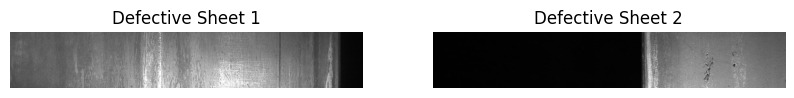

In [ ]:
import os
import random
import pandas as pd
import matplotlib.pyplot as plt
import cv2

# --- 1️⃣ Load CSV ---
csv_path = "/content/steel_data/train.csv"
img_dir = "/content/steel_data/train_images"

train_df = pd.read_csv(csv_path)

# --- 2️⃣ Check basic info ---
train_df['hasDefect'] = train_df['EncodedPixels'].notnull().astype(int)
print(train_df['hasDefect'].value_counts())
print("\nPercentage distribution:")
print(train_df['hasDefect'].value_counts(normalize=True) * 100)

# Create the 'ImageId_ClassId' column by combining 'ImageId' and 'ClassId'
train_df['ImageId_ClassId'] = train_df['ImageId'] + '_' + train_df['ClassId'].astype(str)

# --- 3️⃣ Pick examples ---
# Since there are no non-defective images in this dataset, we only sample defective ones.
defective_imgs = train_df[train_df['hasDefect'] == 1]['ImageId_ClassId'].sample(min(2, len(train_df[train_df['hasDefect'] == 1])), random_state=42).values


# The ImageId_ClassId is like "0002cc93b.jpg_1", so extract filename
def extract_filename(x):
    return x.split('_')[0]

def show_images(img_names, title):
    plt.figure(figsize=(10, 4))
    for i, img_name in enumerate(img_names):
        img_path = os.path.join(img_dir, extract_filename(img_name))
        if os.path.exists(img_path):
            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            plt.subplot(1, len(img_names), i + 1)
            plt.imshow(img)
            plt.title(title + f" {i+1}")
            plt.axis('off')
        else:
            print(f"⚠️ Missing image: {img_path}")
    plt.show()

# --- 4️⃣ Display images ---
show_images(defective_imgs, "Defective Sheet")
# Removed the call to show_images for non-defective images as there are none in this dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

project_path = "/content/drive/MyDrive/Feedstock_ViT_Project"
os.makedirs(project_path, exist_ok=True)

print("✅ Folder created at:", project_path)


✅ Folder created at: /content/drive/MyDrive/Feedstock_ViT_Project


In [ ]:
!cp -r /content/steel_data "/content/drive/MyDrive/Feedstock_ViT_Project/steel_data"


In [ ]:
model.save(f"{project_path}/vision_transformer_defect_model.keras")


In [ ]:
from transformers import TFViTModel, ViTImageProcessor
import tensorflow as tf
from tensorflow import keras

# Recreate the same function used in your model
def vit_features(inputs):
    model_name = "google/vit-base-patch16-224-in21k"
    vit_model = TFViTModel.from_pretrained(model_name)
    outputs = vit_model(inputs, training=False)
    return outputs.last_hidden_state[:, 0, :]  # CLS token


In [ ]:
model = keras.models.load_model(
    "/content/drive/MyDrive/Feedstock_ViT_Project/vision_transformer_defect_model.keras",
    custom_objects={"vit_features": vit_features}
)

print("✅ Model loaded successfully!")


✅ Model loaded successfully!


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 6 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [ ]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import gradio as gr
from PIL import Image

model_path = "/content/drive/MyDrive/Feedstock_ViT_Project/vision_transformer_defect_model.keras"
model = keras.models.load_model(model_path, compile=False)
print("✅ Model loaded successfully!")

IMG_SIZE = 224

def predict_defect(image):
    image = image.convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    img_array = np.expand_dims(np.array(image) / 255.0, axis=0)
    pred = model.predict(img_array, verbose=0)[0][0]
    label = "🟥 Defective Feedstock" if pred > 0.5 else "🟩 Non-Defective Feedstock"
    return {label: float(pred)}

demo = gr.Interface(
    fn=predict_defect,
    inputs=gr.Image(type="pil", label="Upload Feedstock Image"),
    outputs=gr.Label(label="Prediction"),
    title="Vision Transformer - Feedstock Quality Assessment",
    description="Upload a feedstock image to detect surface defects using the trained ViT model."
)

demo.launch(share=True)


TypeError: Could not deserialize class 'Functional' because its parent module tf_keras.src.models.functional cannot be imported. Full object config: {'module': 'keras.src.models.functional', 'class_name': 'Functional', 'config': {'name': 'functional_1', 'trainable': True, 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_shape': [None, 224, 224, 3], 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'input_image'}, 'registered_name': None, 'name': 'input_image', 'inbound_nodes': []}, {'module': 'keras.layers', 'class_name': 'Resizing', 'config': {'name': 'resizing_2', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'height': 224, 'width': 224, 'interpolation': 'bilinear', 'crop_to_aspect_ratio': False, 'pad_to_aspect_ratio': False, 'fill_mode': 'constant', 'fill_value': 0.0, 'antialias': False, 'data_format': 'channels_last'}, 'registered_name': None, 'buil

In [ ]:
!pip install -q tensorflow==2.19.0 keras==3.6.0 tf-keras==2.19.0
import os; os.kill(os.getpid(), 9)


In [ ]:
import keras
print(keras.__version__)   # should print 3.6.0 or newer


3.6.0


In [ ]:
from tensorflow import keras
import tensorflow as tf
from transformers import TFViTModel

# Register the custom function manually in tf.keras
def vit_features(x):
    vit = TFViTModel.from_pretrained("google/vit-base-patch16-224-in21k")
    outputs = vit(pixel_values=x, training=False)
    return outputs.last_hidden_state[:, 0, :]  # CLS token

# Add to global Keras custom objects registry
keras.utils.get_custom_objects()["vit_features"] = vit_features

# Now load your patched model
model = keras.models.load_model("/content/patched_model.keras", compile=False)
print("✅ Model loaded successfully with vit_features registered.")


✅ Model loaded successfully with vit_features registered.


In [ ]:
from tensorflow import keras
import tensorflow as tf
from transformers import TFViTModel
import numpy as np

# Load once globally
vit_model = TFViTModel.from_pretrained("google/vit-base-patch16-224-in21k")

def vit_features(x):
    # Convert to channel-first (B, C, H, W)
    x = tf.transpose(x, perm=[0, 3, 1, 2])
    outputs = vit_model(pixel_values=x, training=False)
    return outputs.last_hidden_state[:, 0, :]  # CLS token

# Register with keras
keras.utils.get_custom_objects()["vit_features"] = vit_features

# Load model
model = keras.models.load_model("/content/patched_model.keras", compile=False)

# Test inference
dummy = np.random.rand(1, 224, 224, 3).astype("float32")
out = model.predict(dummy)
print(out.shape)


All PyTorch model weights were used when initializing TFViTModel.

All the weights of TFViTModel were initialized from the PyTorch model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFViTModel for predictions without further training.


1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
(1, 1)


In [ ]:
!pip install tensorflow==2.15.0 keras==2.15.0



ERROR: Could not find a version that satisfies the requirement tensorflow==2.15.0 (from versions: 2.16.0rc0, 2.16.1, 2.16.2, 2.17.0rc0, 2.17.0rc1, 2.17.0, 2.17.1, 2.18.0rc0, 2.18.0rc1, 2.18.0rc2, 2.18.0, 2.18.1, 2.19.0rc0, 2.19.0, 2.19.1, 2.20.0rc0, 2.20.0)
ERROR: No matching distribution found for tensorflow==2.15.0


In [ ]:
import tensorflow as tf
import tf_keras as keras
print("TensorFlow:", tf.__version__)
print("tf_keras:", keras.__version__)


TensorFlow: 2.18.0
tf_keras: 2.18.0


In [ ]:
from keras.models import load_model
model = load_model("/content/drive/MyDrive/Feedstock_ViT_Project/vision_transformer_defect_model.keras", safe_mode=False)



TypeError: <class 'keras.src.models.functional.Functional'> could not be deserialized properly. Please ensure that components that are Python object instances (layers, models, etc.) returned by `get_config()` are explicitly deserialized in the model's `from_config()` method.

config={'module': 'keras.src.models.functional', 'class_name': 'Functional', 'config': {'name': 'functional_1', 'trainable': True, 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_shape': [None, 224, 224, 3], 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'input_image'}, 'registered_name': None, 'name': 'input_image', 'inbound_nodes': []}, {'module': 'keras.layers', 'class_name': 'Resizing', 'config': {'name': 'resizing_2', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'height': 224, 'width': 224, 'interpolation': 'bilinear', 'crop_to_aspect_ratio': False, 'pad_to_aspect_ratio':

In [ ]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import gradio as gr
from PIL import Image
from transformers import TFViTModel

# Load trained model
model_path = "/content/drive/MyDrive/Feedstock_ViT_Project/vision_transformer_defect_model.keras"
print("🔄 Loading model...")
vit_model = TFViTModel.from_pretrained("google/vit-base-patch16-224-in21k")

# Define global vit_features for compatibility
def vit_features(x):
    x = tf.transpose(x, perm=[0, 3, 1, 2])  # Convert channel-last to channel-first
    outputs = vit_model(pixel_values=x, training=False)
    return outputs.last_hidden_state[:, 0, :]  # CLS token output

keras.utils.get_custom_objects()["vit_features"] = vit_features

# Load your custom model that references vit_features
model = keras.models.load_model(model_path, compile=False)
print("✅ Model loaded successfully!")

IMG_SIZE = 224

# Define prediction function
def predict_defect(image):
    image = image.convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    img_array = np.expand_dims(np.array(image) / 255.0, axis=0)
    pred = model.predict(img_array, verbose=0)[0][0]
    label = "🟥 Defective Feedstock" if pred > 0.5 else "🟩 Non-Defective Feedstock"
    return {label: float(pred)}

# Gradio interface
demo = gr.Interface(
    fn=predict_defect,
    inputs=gr.Image(type="pil", label="Upload Feedstock Image"),
    outputs=gr.Label(label="Prediction"),
    title="Vision Transformer - Feedstock Quality Assessment",
    description="Upload a feedstock image to detect surface defects using the trained ViT model."
)

demo.launch(share=True)


🔄 Loading model...


All PyTorch model weights were used when initializing TFViTModel.

All the weights of TFViTModel were initialized from the PyTorch model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFViTModel for predictions without further training.


TypeError: <class 'keras.src.models.functional.Functional'> could not be deserialized properly. Please ensure that components that are Python object instances (layers, models, etc.) returned by `get_config()` are explicitly deserialized in the model's `from_config()` method.

config={'module': 'keras.src.models.functional', 'class_name': 'Functional', 'config': {'name': 'functional_1', 'trainable': True, 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_shape': [None, 224, 224, 3], 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'input_image'}, 'registered_name': None, 'name': 'input_image', 'inbound_nodes': []}, {'module': 'keras.layers', 'class_name': 'Resizing', 'config': {'name': 'resizing_2', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'height': 224, 'width': 224, 'interpolation': 'bilinear', 'crop_to_aspect_ratio': False, 'pad_to_aspect_ratio':

In [ ]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import gradio as gr
from PIL import Image
from transformers import TFViTModel

# Load trained model
model_path = "/content/drive/MyDrive/Feedstock_ViT_Project/vision_transformer_defect_model.keras"
print("🔄 Loading model...")
vit_model = TFViTModel.from_pretrained("google/vit-base-patch16-224-in21k")

# Define global vit_features for compatibility
def vit_features(x):
    x = tf.transpose(x, perm=[0, 3, 1, 2])  # Convert channel-last to channel-first
    outputs = vit_model(pixel_values=x, training=False)
    return outputs.last_hidden_state[:, 0, :]  # CLS token output

keras.utils.get_custom_objects()["vit_features"] = vit_features

# Load your custom model that references vit_features
model = keras.models.load_model(model_path, compile=False)
print("✅ Model loaded successfully!")

IMG_SIZE = 224

# Define prediction function
def predict_defect(image):
    image = image.convert("RGB").resize((IMG_SIZE, IMG_SIZE))
    img_array = np.expand_dims(np.array(image) / 255.0, axis=0)
    pred = model.predict(img_array, verbose=0)[0][0]
    label = "🟥 Defective Feedstock" if pred > 0.5 else "🟩 Non-Defective Feedstock"
    return {label: float(pred)}

# Gradio interface
demo = gr.Interface(
    fn=predict_defect,
    inputs=gr.Image(type="pil", label="Upload Feedstock Image"),
    outputs=gr.Label(label="Prediction"),
    title="Vision Transformer - Feedstock Quality Assessment",
    description="Upload a feedstock image to detect surface defects using the trained ViT model."
)

demo.launch(share=True)


🔄 Loading model...


All PyTorch model weights were used when initializing TFViTModel.

All the weights of TFViTModel were initialized from the PyTorch model.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFViTModel for predictions without further training.


TypeError: <class 'keras.src.models.functional.Functional'> could not be deserialized properly. Please ensure that components that are Python object instances (layers, models, etc.) returned by `get_config()` are explicitly deserialized in the model's `from_config()` method.

config={'module': 'keras.src.models.functional', 'class_name': 'Functional', 'config': {'name': 'functional_1', 'trainable': True, 'layers': [{'module': 'keras.layers', 'class_name': 'InputLayer', 'config': {'batch_shape': [None, 224, 224, 3], 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'input_image'}, 'registered_name': None, 'name': 'input_image', 'inbound_nodes': []}, {'module': 'keras.layers', 'class_name': 'Resizing', 'config': {'name': 'resizing_2', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'height': 224, 'width': 224, 'interpolation': 'bilinear', 'crop_to_aspect_ratio': False, 'pad_to_aspect_ratio':